In [172]:
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

life_and_gdp = pd.read_csv("all_data.csv")

Has life expectancy increased over time in the six nations? Yes
Has GDP increased over time in the six nations? Yes
Is there a correlation between GDP and life expectancy of a country? It is likely.
What is the average life expectancy in these nations? 50-79 years
What is the distribution of that life expectancy? skewed to the left

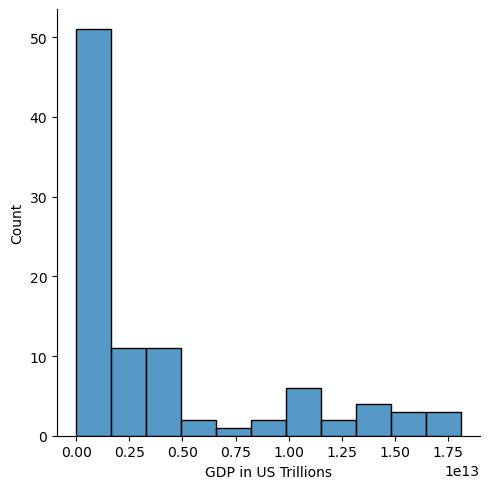

In [156]:
life_and_gdp.columns=["country", "year", "life_expect", "gdp"]

sns.displot(data = life_and_gdp, x="gdp", kde=False)
plt.xlabel("GDP in US Trillions")
plt.show()
plt.close()

Shows distribution of GDP in US Trillions. Shows that the distribution of GDP is skewed-right.

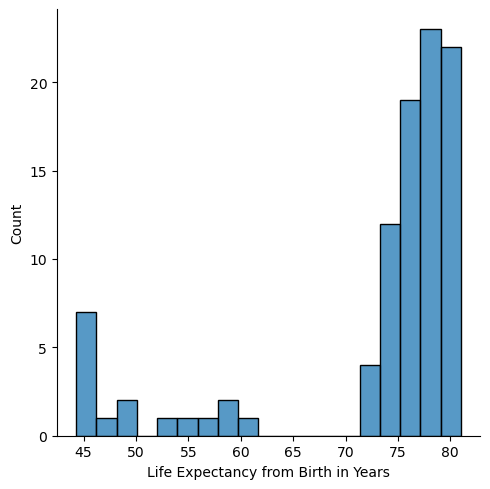

In [24]:
sns.displot(data= life_and_gdp, x="life_expect", kde=False)
plt.xlabel("Life Expectancy from Birth in Years")
plt.show()
plt.close()

Shows the distribution of Life Expectancy from Birth over all six countries. Distribution is skewed-left for thw most part, with no data in the middle and a small right-skew from what is likely the Zimbabwe data.

In [35]:
life_and_gdp_no_yr = life_and_gdp.drop("year", axis=1)
life_and_gdp_means = life_and_gdp_no_yr.groupby("country").mean()
print(life_and_gdp_means)

                          life_expect           gdp
country                                            
Chile                        78.94375  1.697888e+11
China                        74.26250  4.957714e+12
Germany                      79.65625  3.094776e+12
Mexico                       75.71875  9.766506e+11
United States of America     78.06250  1.407500e+13
Zimbabwe                     50.09375  9.062580e+09


Shows the means of life expectency and gdp for each of the six countries. Life expectancy ranges from 50 years to just under 79.6 years.

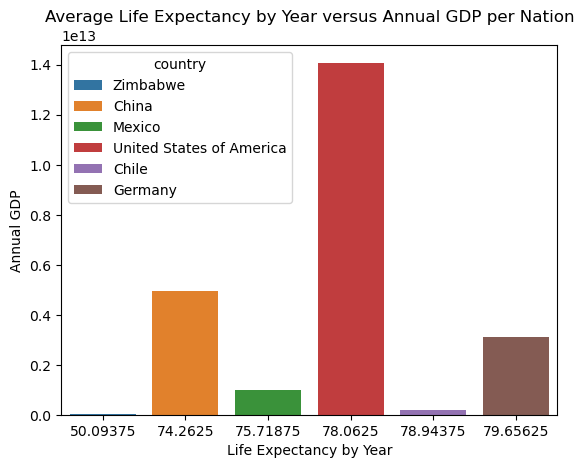

In [95]:
sns.barplot(x='life_expect', y='gdp', hue='country', data=life_and_gdp_means)
plt.xlabel('Life Expectancy by Year')
plt.ylabel('Annual GDP')
plt.title('Average Life Expectancy by Year versus Annual GDP per Nation')
plt.show()
plt.close()

This graph shows a visual of each country's annual GDP and average life expectancy. As per this graph, highest GDP does not mean highest life expectancy, nor vice versa, with Chile having the second lowest average annual GDP but the second highest average life expectancy.

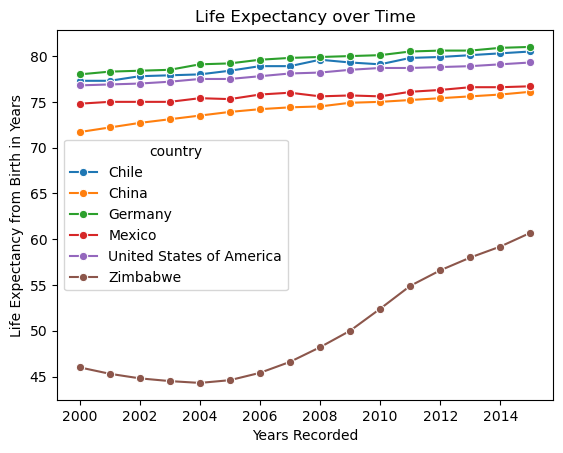

In [158]:
sns.lineplot(y="life_expect", x= "year", hue="country", data=life_and_gdp, marker="o")
plt.ylabel("Life Expectancy from Birth in Years")
plt.xlabel("Years Recorded")
plt.title("Life Expectancy over Time")
plt.savefig('life_expect_over_time.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

This plot shows life expectancy over all 16 recorded years. Zimbabwe had the steepest climb, though it also had a dip or was in a dip in 2000, meaning it actually only started rising in 2005 at a life expectancy of around 45 years, until the data stops in 2015, at a life expectancy of around 60 years. The other 5 countries also showed climbs in life expectancy over time, however none as steep as Zimbabwe.

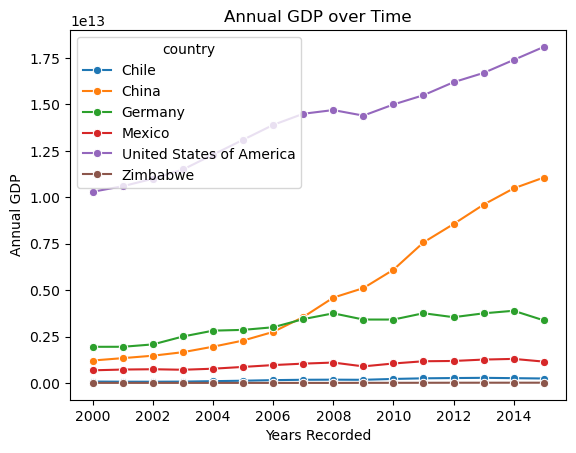

In [98]:
sns.lineplot(x='year', y='gdp', hue='country', data=life_and_gdp, marker='o')
plt.xlabel("Years Recorded")
plt.ylabel("Annual GDP")
plt.title("Annual GDP over Time")
plt.show()
plt.close()

Counter to the previous plot, this one shows each countries annual GDP over the recorded 16 years. While Zimbabwe didn't seem to see with an increase or decrese in annual GDP for 16 years, China and the USA both showed steep climbs. 

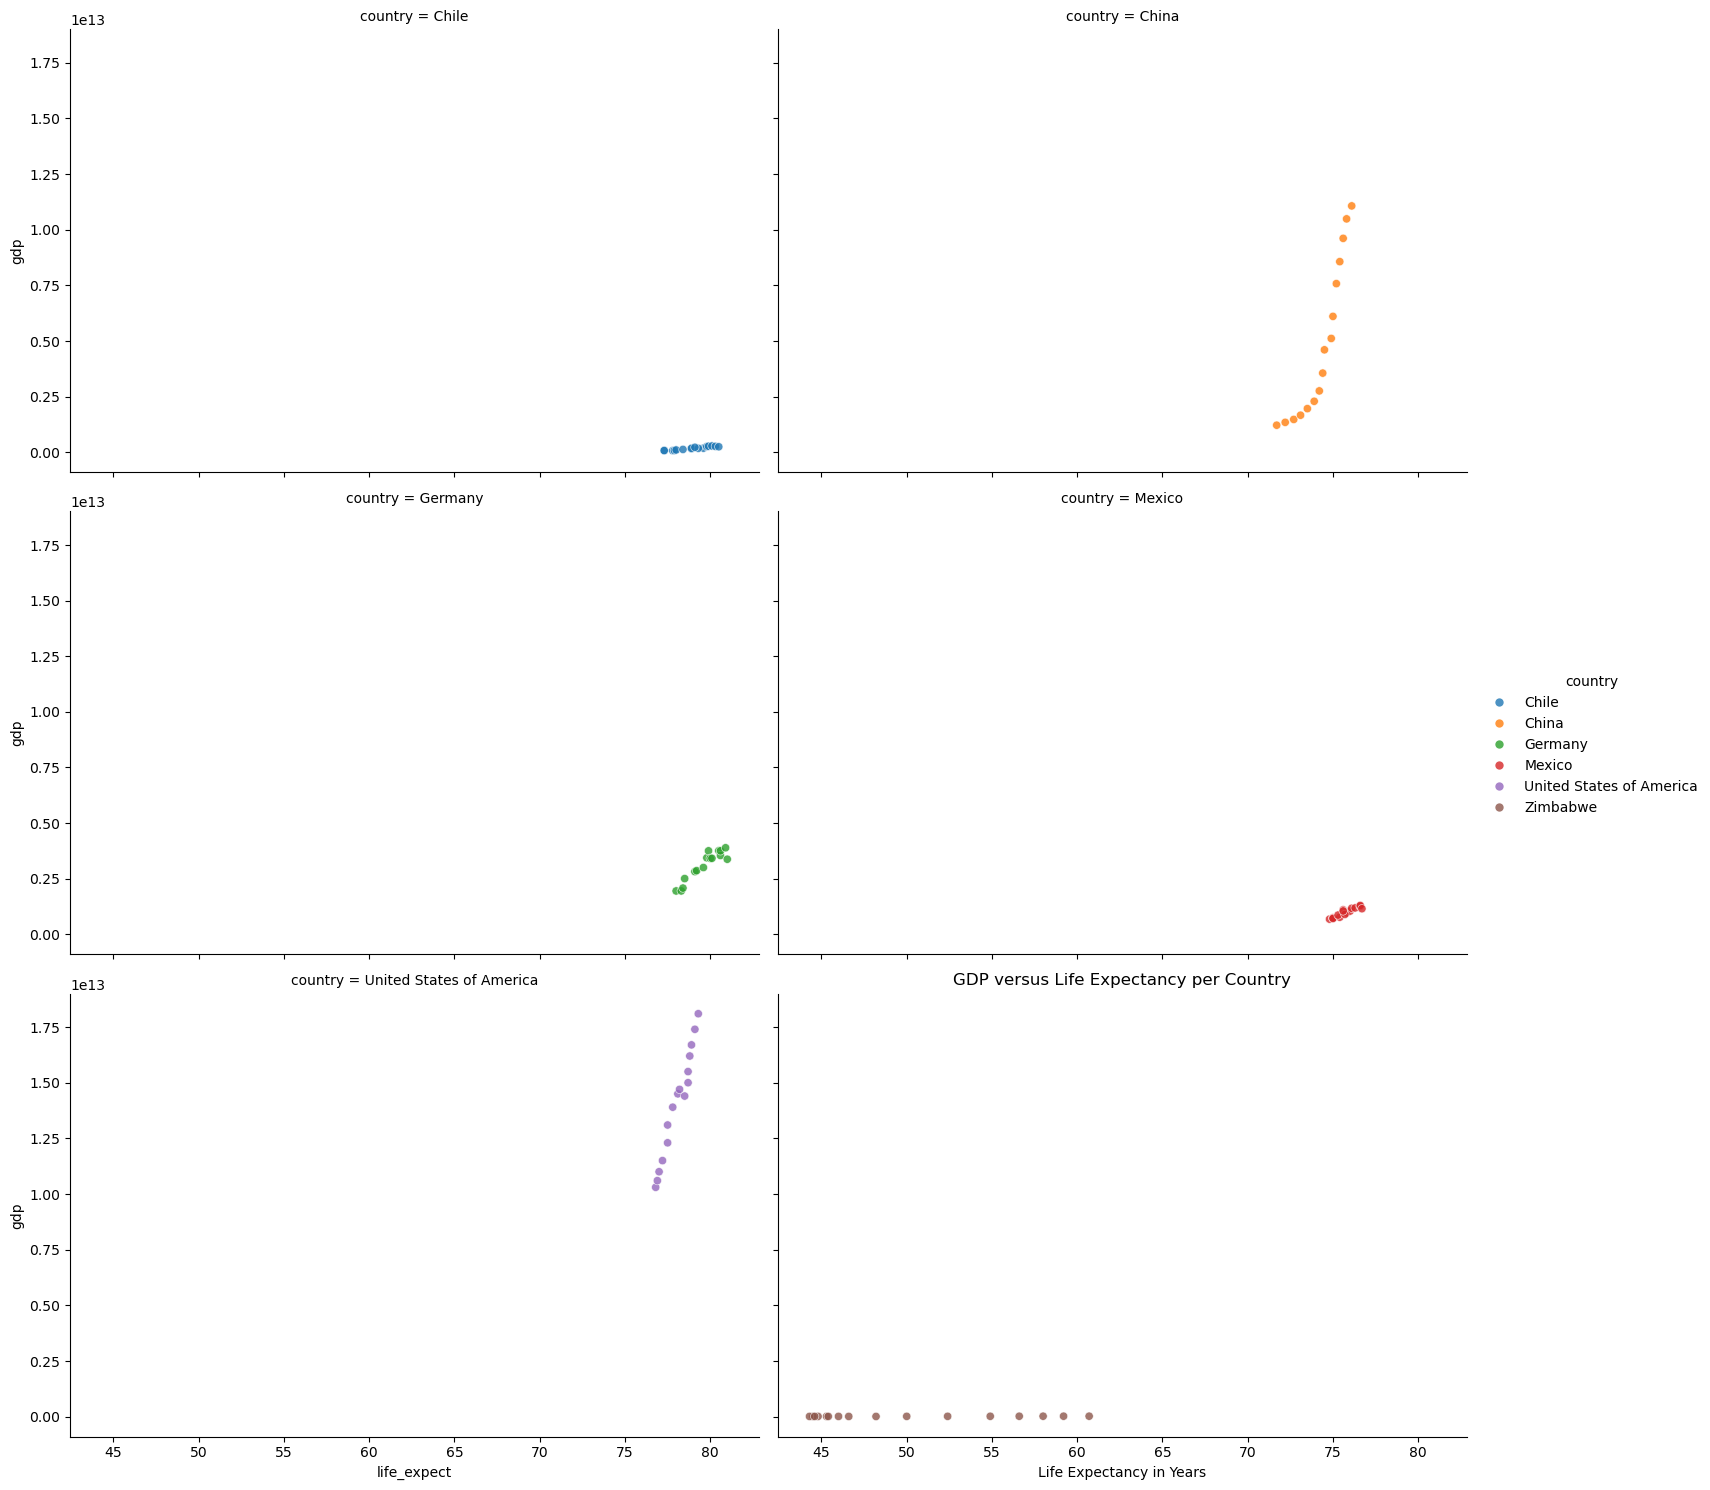

In [171]:
sns.relplot(x='life_expect', y='gdp', data=life_and_gdp, hue='country', col='country', col_wrap=2, alpha=.8, height=5, aspect=1.5)
plt.title("GDP versus Life Expectancy per Country")
plt.xlabel("Life Expectancy in Years")
plt.ylabel("GDP in US Trillions")
plt.savefig("life expect vs gdp scatter.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

Shows distribution of life expectancy over time for each of the six countries. Based on looking at the disrtibution for China and the USA, you would think that there is a plateu for life expectancy that they both hit close to 75 years. Looking at these scatter plots, it would be exptremely difficult to say whether there is an association bewteen GDP and life expectancy, due to Zimbabwe's life expectancy rising, but their GDP seemingly not moving at all.

In [154]:
for country, group in life_and_gdp.groupby("country"):
    gdp_life_expect_association, p = pearsonr(group.gdp, group.life_expect)
    print(country)
    print(f"pearson correlation = {gdp_life_expect_association:.3f}")
    print(f"p-value = {p:.4e}\n")

Chile
pearson correlation = 0.950
p-value = 1.8659e-08

China
pearson correlation = 0.909
p-value = 1.1251e-06

Germany
pearson correlation = 0.933
p-value = 1.4019e-07

Mexico
pearson correlation = 0.932
p-value = 1.4687e-07

United States of America
pearson correlation = 0.982
p-value = 1.7500e-11

Zimbabwe
pearson correlation = 0.966
p-value = 1.2359e-09



The closer the pearson correlation is to 0, the less chance there is of correlation - as such, due to every country having an r-value of at least 0.9, we can say that it is highly likely that there is a positive association between gdp and life expectancy.
The p-value is the opposite, the closer to 0 the value is, the higher the chance of association being real and not due to random chance - as such, with every country having p-values of less that 1 from -6 decimal points to -11, it can be said that there is a very low chance that the r-value is due to random variation alone.
Therefore, it is reasonable to say that statistically, there is a positive association between GDP and life expecancy.